# Practical Lab 2: Multivariate Linear Regression, Non-Parametric Models and Cross-Validation

**Course:** CSCN8010 – Foundations of Machine Learning Frameworks  
**Professor:** David Espinosa Carrillo  
**Student:** Juan Antonio Sainz Gálvez  
**Student ID:** 9072844  
**Repository:** https://github.com/antoniosg2025-stack/CSCN8010_PracticalLab2_DiabetesRegression.git

---

**Report structure**

- **Part 1 – Data and problem:** get the data, frame the problem, EDA, cleaning, train/validation/test split.
- **Part 2 – Univariate polynomial regression on BMI:** degrees 0–5, comparison table, model selection, test results, plot, equation, prediction, trainable parameters, conclusions.
- **Part 3 – Multivariate models:** two polynomial models, two decision trees, two kNNs and two logistic regression models, following the same steps.
- **Cross-validation:** 5-fold cross-validation is used as a robustness check of every model selection.
- **Final conclusions.**

## Setup

All libraries used in the report are imported once here. A single `RANDOM_STATE` is used everywhere so that every number in this report can be reproduced.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn import datasets
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import (r2_score, mean_absolute_error, mean_absolute_percentage_error,
                             accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# Part 1 – Data, Problem Framing and Exploration

## 1. Get the data

The dataset is loaded with `datasets.load_diabetes()`. Two optional arguments are used:

- `as_frame=True` returns a pandas DataFrame, which makes exploration easier.
- `scaled=False` returns the measurements in their **original clinical units** (age in years, BMI in kg/m², blood pressure in mm Hg, serum values in their lab units).

By default scikit-learn returns every feature mean-centred and scaled so that its sum of squares equals 1. That version is convenient for linear algebra, but it makes the model equation and the prediction for "a BMI of 30" impossible to read clinically. Keeping the original units makes Part 2 interpretable; scaling is applied later **inside the model pipelines**, only where the algorithm needs it (kNN, logistic regression, multivariate polynomials) and always fitted on the training set only.

In [2]:
diabetes = datasets.load_diabetes(as_frame=True, scaled=False)
df = diabetes.frame.rename(columns={"target": "progression"})

print("Shape (rows, columns):", df.shape)
display(df.head())

Shape (rows, columns): (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,59.000,2.000,32.100,101.000,157.000,93.200,38.000,4.000,4.860,87.000,151.000
1,48.000,1.000,21.600,87.000,183.000,103.200,70.000,3.000,3.892,69.000,75.000
2,72.000,2.000,30.500,93.000,156.000,93.600,41.000,4.000,4.673,85.000,141.000
3,24.000,1.000,25.300,84.000,198.000,131.400,40.000,5.000,4.890,89.000,206.000
4,50.000,1.000,23.000,101.000,192.000,125.400,52.000,4.000,4.290,80.000,135.000


**Variable dictionary** (from the scikit-learn dataset description):

| Column | Meaning |
|---|---|
| `age` | age in years |
| `sex` | sex, coded as 1 or 2 |
| `bmi` | body mass index (kg/m²) |
| `bp` | average blood pressure (mm Hg) |
| `s1` | tc – total serum cholesterol |
| `s2` | ldl – low-density lipoproteins |
| `s3` | hdl – high-density lipoproteins |
| `s4` | tch – total cholesterol / HDL ratio |
| `s5` | ltg – log of serum triglycerides level |
| `s6` | glu – blood sugar level |
| `progression` | **target**: quantitative measure of disease progression one year after baseline |

## 2. Frame the problem

**Goal.** Build a model that predicts *disease progression one year after baseline* from ten baseline measurements, to be used as a **screening tool** that helps physicians identify patients at risk.

**Type of task.**
- The target is a continuous number (25 to 346), so the core task is **supervised regression**. Polynomial regression, decision trees and kNN regressors are evaluated with R², MAE and MAPE.
- A screening decision is ultimately binary ("flag this patient for follow-up or not"). For the logistic regression models in Part 3 the target is converted into a **high-risk / low-risk class**, which turns the problem into a **binary classification** task.

**Talking points from the course workshops**

- *Performance Metrics Classification workshop.* A single accuracy number hides the type of mistake. For screening, a **false negative** (a high-risk patient sent home) is more costly than a false positive (an extra follow-up visit). For the classification models we therefore read the **confusion matrix** and favour **recall** (sensitivity) on the high-risk class, together with precision and F1. For the regression models the same idea appears as: large errors on patients with high progression are the most dangerous ones.
- *K-Nearest Neighbors workshop.* kNN predicts by averaging the most similar patients. It uses distances, so features must be on a **comparable scale** (cholesterol in the hundreds would otherwise dominate BMI). The value of *k* controls the bias–variance trade-off: small *k* follows noise, large *k* oversmooths.
- *Logistic Regression Classifier workshop.* Logistic regression models the **probability** of the positive class through the sigmoid of a linear combination of features. Its coefficients are interpretable (direction and strength of each risk factor on the log-odds), and the **decision threshold** (0.5 by default) can be moved to trade precision for recall – useful when missing a patient is expensive.

**How success is measured.**
- **R²** – share of the variance in progression explained by the model (1 is perfect, 0 equals predicting the mean).
- **MAE** – average absolute error, in the same units as the target ("progression points").
- **MAPE** – average error as a percentage of the true value. It penalises errors on patients with *low* progression heavily, because they have a small denominator.
- **Model selection** is done on the **validation set**; the **test set** is used only once, on the chosen model.

## 3. Exploratory Data Analysis

### 3.1 Data types and descriptive statistics

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          442 non-null    float64
 1   sex          442 non-null    float64
 2   bmi          442 non-null    float64
 3   bp           442 non-null    float64
 4   s1           442 non-null    float64
 5   s2           442 non-null    float64
 6   s3           442 non-null    float64
 7   s4           442 non-null    float64
 8   s5           442 non-null    float64
 9   s6           442 non-null    float64
 10  progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [4]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,442.000,48.518,13.109,19.000,38.250,50.000,59.000,79.000
sex,442.000,1.468,0.500,1.000,1.000,1.000,2.000,2.000
bmi,442.000,26.376,4.418,18.000,23.200,25.700,29.275,42.200
bp,442.000,94.647,13.831,62.000,84.000,93.000,105.000,133.000
s1,442.000,189.140,34.608,97.000,164.250,186.000,209.750,301.000
s2,442.000,115.439,30.413,41.600,96.050,113.000,134.500,242.400
s3,442.000,49.788,12.934,22.000,40.250,48.000,57.750,99.000
s4,442.000,4.070,1.290,2.000,3.000,4.000,5.000,9.090
s5,442.000,4.641,0.522,3.258,4.277,4.620,4.997,6.107
s6,442.000,91.260,11.496,58.000,83.250,91.000,98.000,124.000


**Observations**
- 442 patients, 10 numeric features and 1 numeric target. All columns are numeric (`float64`).
- `sex` is a binary code (1 or 2) with a roughly balanced split (235 vs 207).
- BMI ranges from 18 to 42.2 kg/m² (median 25.7): from normal weight to severe obesity.
- The target `progression` ranges from 25 to 346 with mean 152 and a large standard deviation (77), so the patients are very heterogeneous.

### 3.2 Histograms

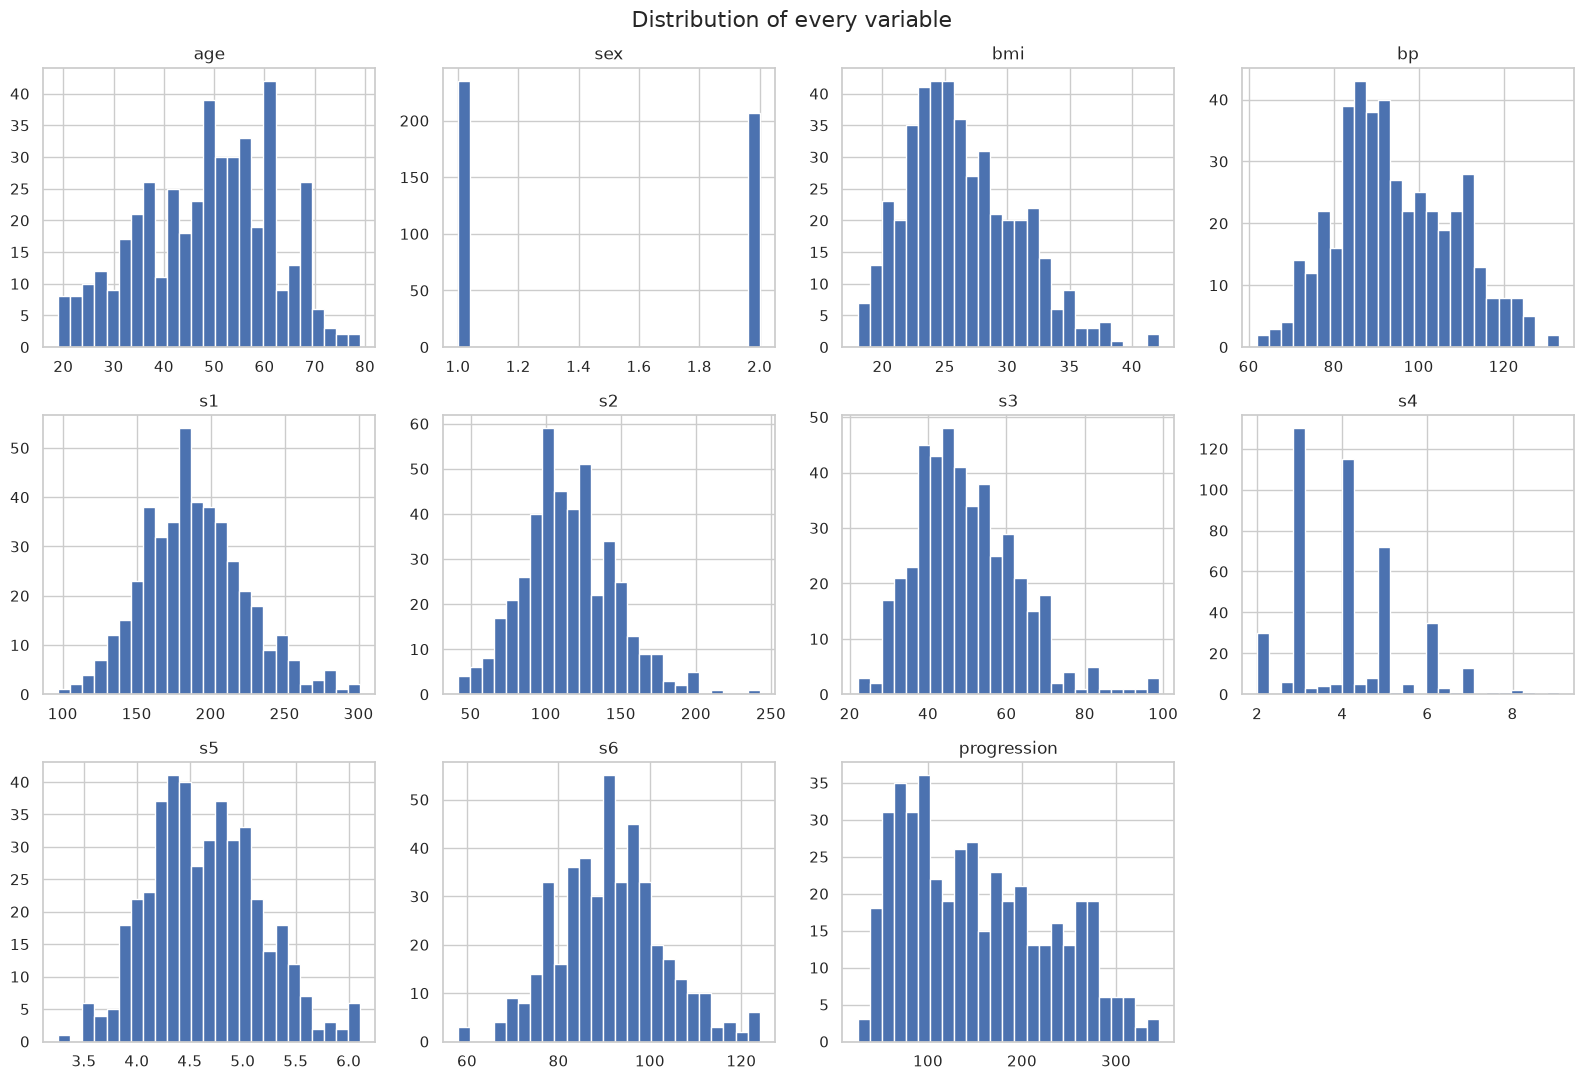

In [5]:
axes = df.hist(bins=25, figsize=(16, 11), color="#4C72B0", edgecolor="white", layout=(3, 4))
plt.suptitle("Distribution of every variable", fontsize=16)
plt.tight_layout()
plt.show()

**Insights**
- `progression` is **right-skewed**: many patients have low or moderate progression and fewer have very high values.
- `bmi`, `s5` and `s6` are close to bell-shaped; `bmi` and `s3` show a longer right tail.
- `s4` (cholesterol/HDL ratio) takes a few discrete values, which is visible as tall separated bars.
- `sex` only has two values, so it is a categorical variable coded as a number.

### 3.3 Scatter plots against the target

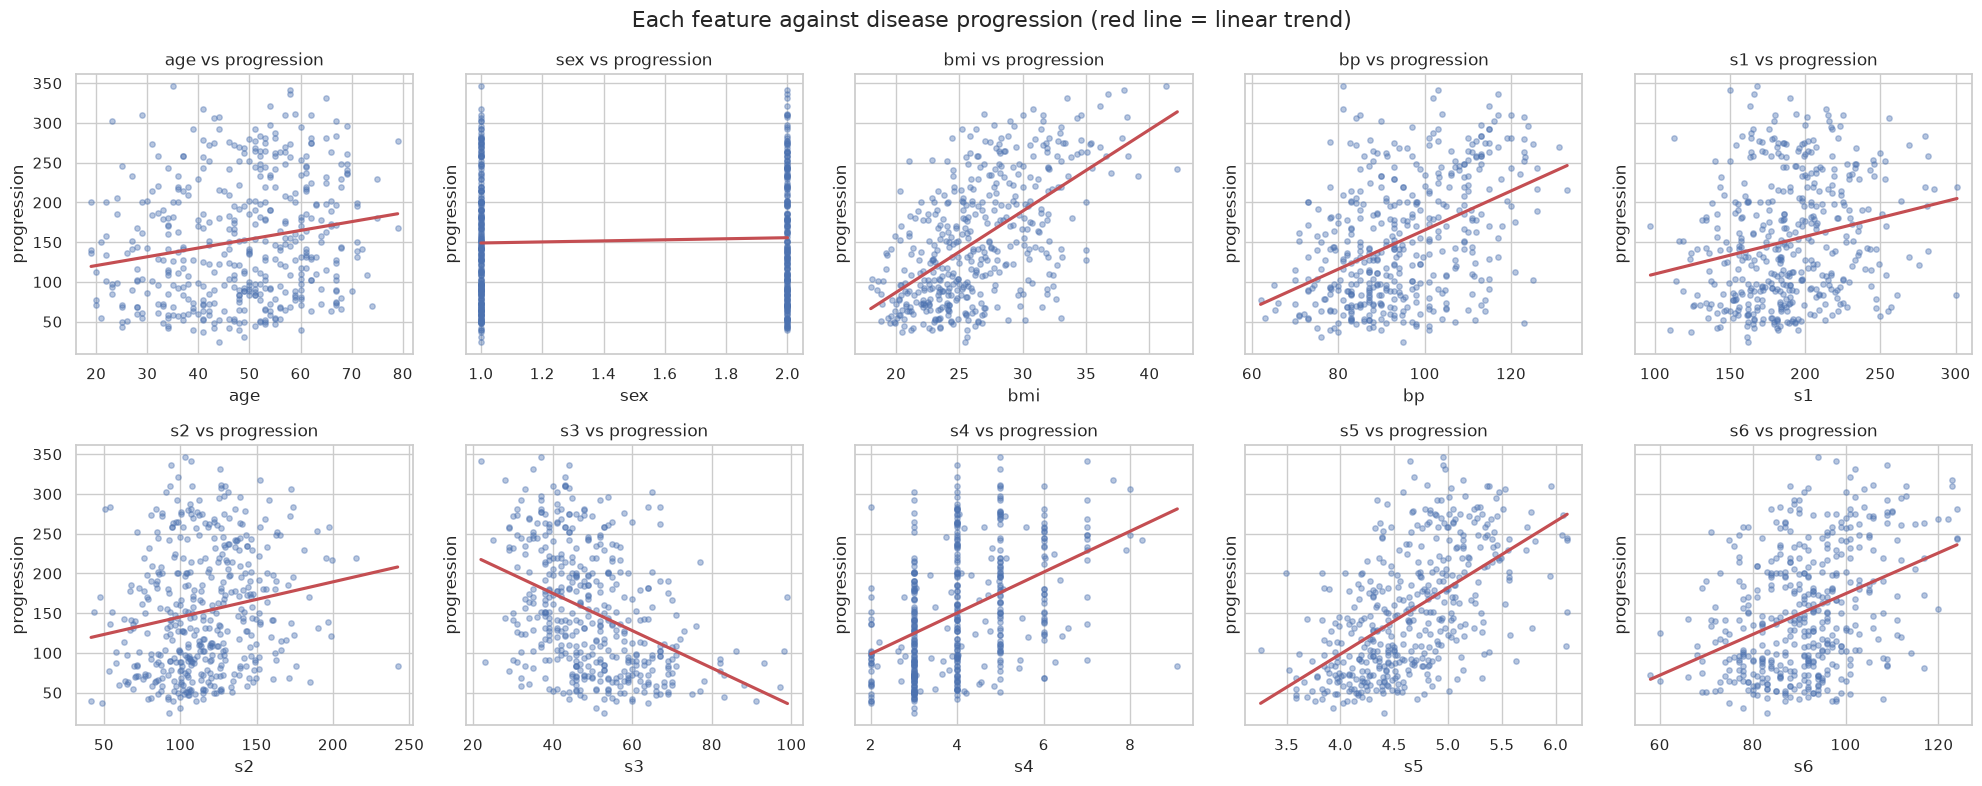

In [6]:
features = [c for c in df.columns if c != "progression"]
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharey=True)
for ax, col in zip(axes.ravel(), features):
    sns.regplot(data=df, x=col, y="progression", ax=ax, scatter_kws={"alpha": 0.4, "s": 15},
                line_kws={"color": "#C44E52"}, ci=None)
    ax.set_title(f"{col} vs progression")
plt.suptitle("Each feature against disease progression (red line = linear trend)", fontsize=16)
plt.tight_layout()
plt.show()

**Insights**
- `bmi` and `s5` show the clearest **positive** trends: higher BMI and higher triglycerides go with faster progression.
- `bp` and `s4` show weaker positive trends; `s3` (HDL, "good" cholesterol) shows a **negative** trend.
- In every panel the cloud of points around the trend line is **wide**: at a fixed BMI, progression can vary by more than 200 points. A single feature will therefore only explain part of the variability.

### 3.4 Correlation matrix

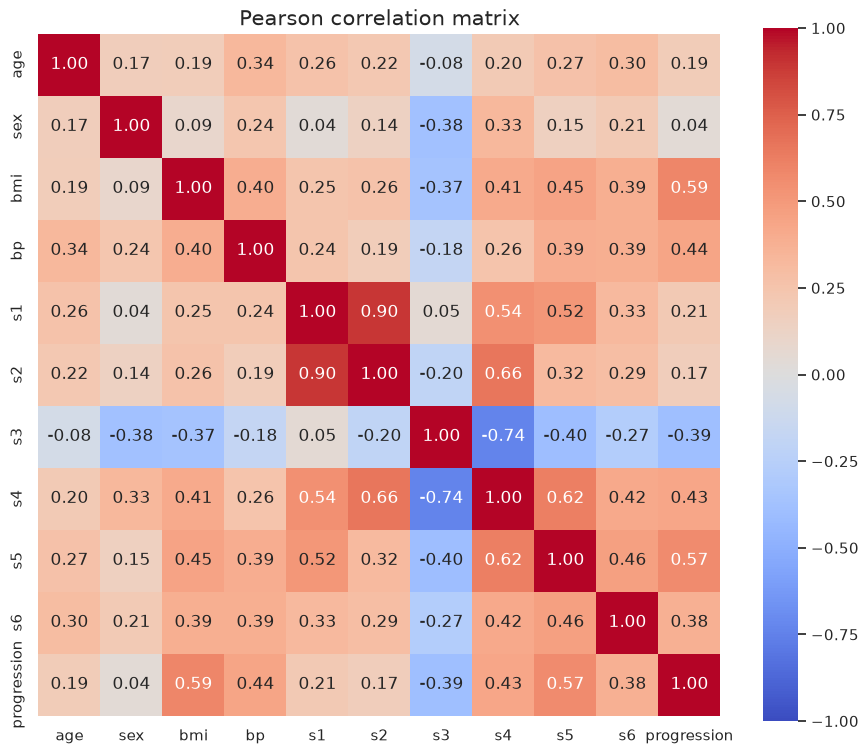

Correlation of each feature with the target:


,r with progression
bmi,0.586
s5,0.566
bp,0.441
s4,0.430
s6,0.382
s1,0.212
age,0.188
s2,0.174
sex,0.043
s3,-0.395


In [7]:
corr = df.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Pearson correlation matrix", fontsize=15)
plt.show()

print("Correlation of each feature with the target:")
display(corr["progression"].drop("progression").sort_values(ascending=False).to_frame("r with progression"))

**Insights**
- The strongest predictors of progression are **`bmi` (r = 0.59)** and **`s5` (r = 0.57)**, followed by `bp` (0.44) and `s4` (0.43). `s3` has a moderate negative correlation (−0.39). `sex` has almost no linear relationship with the target (0.04).
- This confirms the assignment's choice of **BMI** as the single feature for Part 2.
- **Multicollinearity:** `s1` and `s2` are strongly correlated (0.90), and `s3`–`s4` are strongly negatively correlated (−0.74). These pairs carry overlapping information. This does not hurt prediction much, but it makes individual linear coefficients unstable and it inflates the number of redundant terms in a polynomial expansion.

## 4. Data cleaning

In [8]:
print("Missing values per column:")
print(df.isna().sum().to_string())
print("\nFully duplicated rows:", df.duplicated().sum())

# Outlier screen with the 1.5 x IQR rule (informative only)
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
outliers = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum()
print("\nValues outside 1.5 x IQR per column:")
print(outliers.to_string())

Missing values per column:
age            0
sex            0
bmi            0
bp             0
s1             0
s2             0
s3             0
s4             0
s5             0
s6             0
progression    0

Fully duplicated rows: 0

Values outside 1.5 x IQR per column:
age            0
sex            0
bmi            3
bp             0
s1             8
s2             7
s3             7
s4             2
s5             4
s6             9
progression    0


**Cleaning decisions**
- **No missing values and no duplicated rows** → no imputation or removal is needed.
- The IQR screen flags a few extreme values (for example in `s1`, `s2`, `s3` and `s6`). They are **plausible clinical measurements**, not data-entry errors, and in a screening context extreme patients are exactly the ones we must not ignore. With only 442 patients, removing them would also cost data. **They are kept.**
- **No scaling is applied to the DataFrame itself.** Scaling is done inside each model pipeline and fitted on the training data only, which avoids leaking information from the validation and test sets.
- `sex` is kept as its 1/2 code: with two levels a numeric code is equivalent to a dummy variable for linear models and trees.

**Conclusion:** the dataset is already clean; the original values are used without modification.

## 5. Train / validation / test split (75% / 10% / 15%)

The split is done in two steps with a fixed seed:
1. 15% of the patients are held out as the **test set**.
2. From the remaining 85%, a fraction 0.10/0.85 is taken as the **validation set**, which is 10% of the full dataset. The rest (75%) is the **training set**.

In [9]:
X = df.drop(columns="progression")
y = df["progression"]

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.10 / 0.85, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "Set": ["Train", "Validation", "Test"],
    "Patients": [len(X_train), len(X_val), len(X_test)],
})
split_summary["Share of dataset (%)"] = 100 * split_summary["Patients"] / len(df)
split_summary["Mean progression"] = [y_train.mean(), y_val.mean(), y_test.mean()]
display(split_summary)

assert len(X_train) + len(X_val) + len(X_test) == len(df)
assert set(X_train.index).isdisjoint(X_val.index) and set(X_train.index).isdisjoint(X_test.index) \
       and set(X_val.index).isdisjoint(X_test.index)
print("Split check passed: the three sets are disjoint and cover all patients.")

,Set,Patients,Share of dataset (%),Mean progression
0,Train,330,74.661,153.045
1,Validation,45,10.181,153.289
2,Test,67,15.158,146.866


Split check passed: the three sets are disjoint and cover all patients.


The three sets have 330, 45 and 67 patients. Note that the **validation set is small (45 patients)**: metrics computed on it are noisy, which is why 5-fold cross-validation on the 85% train+validation data is added as a second opinion for every model choice.

### Helper functions

Small helpers keep the evaluation identical for every model.

In [10]:
def regression_metrics(model, X_, y_):
    # R-squared, MAE and MAPE (%) of a fitted regression model on one data set.
    pred = model.predict(X_)
    return {"R²": r2_score(y_, pred),
            "MAE": mean_absolute_error(y_, pred),
            "MAPE (%)": 100 * mean_absolute_percentage_error(y_, pred)}


def train_val_table(models, X_tr, y_tr, X_va, y_va):
    # One row per model with training and validation metrics side by side.
    rows = []
    for name, model in models.items():
        tr = regression_metrics(model, X_tr, y_tr)
        va = regression_metrics(model, X_va, y_va)
        rows.append({"Model": name,
                     "Train R²": tr["R²"], "Val R²": va["R²"],
                     "Train MAE": tr["MAE"], "Val MAE": va["MAE"],
                     "Train MAPE (%)": tr["MAPE (%)"], "Val MAPE (%)": va["MAPE (%)"]})
    return pd.DataFrame(rows).set_index("Model")


CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_table(models, X_, y_):
    # 5-fold cross-validated R², MAE and MAPE on the train+validation data (85%).
    rows = []
    for name, model in models.items():
        s = cross_validate(model, X_, y_, cv=CV,
                           scoring={"r2": "r2", "mae": "neg_mean_absolute_error",
                                    "mape": "neg_mean_absolute_percentage_error"})
        rows.append({"Model": name,
                     "CV R² (mean)": s["test_r2"].mean(), "CV R² (std)": s["test_r2"].std(),
                     "CV MAE (mean)": -s["test_mae"].mean(),
                     "CV MAPE % (mean)": -100 * s["test_mape"].mean()})
    return pd.DataFrame(rows).set_index("Model")

# Part 2 – Univariate Polynomial Regression on BMI

## 6. Models: polynomial degrees 0 to 5

Each model is a pipeline of `PolynomialFeatures(degree=d)` followed by `LinearRegression(fit_intercept=False)`. `PolynomialFeatures` already creates the constant column `1` (the bias), so the intercept is learned as the coefficient of that column. This keeps one clean coefficient per polynomial term, which makes the equation (step 11) and the parameter count (step 13) easy to read.

Degree 0 contains only the constant term, so it always predicts the training mean: it is the **baseline** every other model must beat.

In [11]:
X_train_bmi, X_val_bmi, X_test_bmi = X_train[["bmi"]], X_val[["bmi"]], X_test[["bmi"]]

bmi_models = {}
for degree in range(6):
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=True)),
        ("linreg", LinearRegression(fit_intercept=False)),
    ])
    model.fit(X_train_bmi, y_train)
    bmi_models[f"Degree {degree}"] = model

print("Fitted models:", list(bmi_models))

Fitted models: ['Degree 0', 'Degree 1', 'Degree 2', 'Degree 3', 'Degree 4', 'Degree 5']


## 7. Training vs validation comparison

In [12]:
bmi_table = train_val_table(bmi_models, X_train_bmi, y_train, X_val_bmi, y_val)
display(bmi_table)

,Train R²,Val R²,Train MAE,Val MAE,Train MAPE (%),Val MAPE (%)
Model,,,,,,
Degree 0,0.000,-0.000,66.548,63.447,63.352,58.793
Degree 1,0.354,0.449,52.278,41.998,48.462,40.445
Degree 2,0.355,0.449,52.267,41.758,48.448,40.310
Degree 3,0.355,0.448,52.239,41.765,48.395,40.291
Degree 4,0.355,0.448,52.243,41.737,48.398,40.276
Degree 5,0.355,0.449,52.231,41.802,48.408,40.321


**Reading the table**
- **Degree 0** has R² = 0 on training (by definition) and about 0 on validation, with a validation MAE of about 63 points. This is the baseline.
- Going from degree 0 to **degree 1** is the big jump: validation R² rises to about 0.45 and validation MAE falls to about 42 points.
- **Degrees 2 to 5 add almost nothing.** Training R² only moves in the third decimal (0.354 → 0.355) and validation R² stays between 0.448 and 0.449. The relation between BMI and progression in this data is essentially **linear**; the extra curvature mostly fits noise.
- Validation scores are *better* than training scores. This is not a sign of a perfect model: the validation set has only 45 patients and happens to be easier than average. The cross-validation below checks this.

In [13]:
bmi_cv = cv_table(bmi_models, X_trainval[["bmi"]], y_trainval)
display(bmi_cv)

,CV R² (mean),CV R² (std),CV MAE (mean),CV MAPE % (mean)
Model,,,,
Degree 0,-0.022,0.025,66.522,63.132
Degree 1,0.344,0.067,51.431,47.600
Degree 2,0.341,0.068,51.500,47.666
Degree 3,0.341,0.068,51.486,47.625
Degree 4,0.341,0.068,51.479,47.623
Degree 5,0.342,0.068,51.452,47.629


Cross-validation over the 85% train+validation data confirms the picture with a more realistic level: the average R² is about **0.34** for every degree from 1 to 5 (the 45-patient validation set was optimistic), and higher degrees do not help. Degree 1 has the best cross-validated R², so both evaluations agree.

## 8. Best model

**Selection rule used throughout this report**
1. Rank the models with the validation table.
2. When several models are within a negligible margin (here, less than 0.01 in validation R²), prefer the **simplest** one (Occam's razor), because extra terms increase variance without improving accuracy.
3. Because the validation set has only 45 patients, the choice is checked against 5-fold cross-validation on the 375 train+validation patients. If the two disagree, cross-validation decides, since it averages five evaluations instead of one.

In [14]:
best_val_r2 = bmi_table["Val R²"].max()
candidates = bmi_table[bmi_table["Val R²"] >= best_val_r2 - 0.01]
best_name = candidates.index[0]          # models are ordered by degree, so this is the simplest
best_bmi_model = bmi_models[best_name]

print("Models within 0.01 of the best validation R²:", list(candidates.index))
print("Selected model:", best_name)
display(bmi_table.loc[[best_name]])

Models within 0.01 of the best validation R²: ['Degree 1', 'Degree 2', 'Degree 3', 'Degree 4', 'Degree 5']
Selected model: Degree 1


,Train R²,Val R²,Train MAE,Val MAE,Train MAPE (%),Val MAPE (%)
Model,,,,,,
Degree 1,0.354,0.449,52.278,41.998,48.462,40.445


**Selected model: Degree 1 (simple linear regression on BMI).** Its validation R² (0.449) and MAE (≈42.0) are practically identical to the best higher-degree models, its cross-validated R² (0.344) is the best of all degrees, and it has only two parameters. A straight line is also the easiest model for a physician to understand and trust.

## 9. Test-set evaluation of the chosen model

In [15]:
test_bmi = pd.DataFrame([regression_metrics(best_bmi_model, X_test_bmi, y_test)], index=[best_name])
comparison = pd.DataFrame([regression_metrics(best_bmi_model, X_train_bmi, y_train),
                           regression_metrics(best_bmi_model, X_val_bmi, y_val),
                           regression_metrics(best_bmi_model, X_test_bmi, y_test)],
                          index=["Train", "Validation", "Test"])
display(comparison)

,R²,MAE,MAPE (%)
Train,0.354,52.278,48.462
Validation,0.449,41.998,40.445
Test,0.204,54.934,48.750


**Test results (Degree 1):** R² ≈ 0.20, MAE ≈ 54.9 points, MAPE ≈ 48.8%.

The test performance is clearly **lower** than the validation performance (R² 0.45). With 45 and 67 patients, each set can be easier or harder by chance; the cross-validated R² (≈0.33) lies between both and is the most reliable estimate. In practical terms, BMI alone predicts progression with an average error of roughly **50 points** on a scale whose standard deviation is 77.

## 10. Plot of the fitted model over train, validation and test data

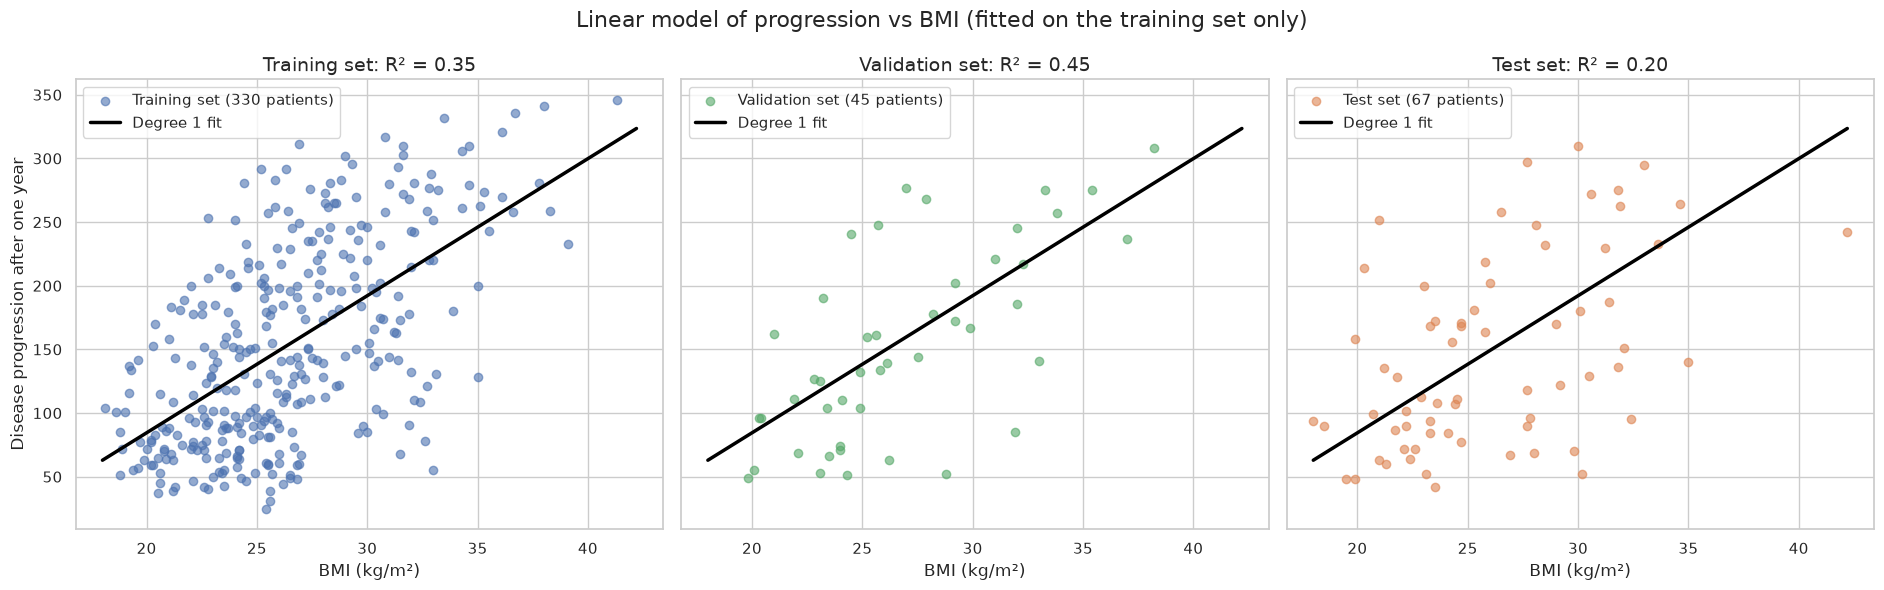

In [16]:
bmi_grid = pd.DataFrame({"bmi": np.linspace(X["bmi"].min(), X["bmi"].max(), 300)})
curve = best_bmi_model.predict(bmi_grid)

sets = [("Training set", X_train_bmi, y_train, "#4C72B0"),
        ("Validation set", X_val_bmi, y_val, "#55A868"),
        ("Test set", X_test_bmi, y_test, "#DD8452")]
fig, axes = plt.subplots(1, 3, figsize=(19, 6), sharex=True, sharey=True)
for ax, (title, Xs, ys, color) in zip(axes, sets):
    ax.scatter(Xs["bmi"], ys, alpha=0.6, color=color, label=f"{title} ({len(ys)} patients)")
    ax.plot(bmi_grid["bmi"], curve, color="black", linewidth=2.5, label=f"{best_name} fit")
    ax.set_title(f"{title}: R² = {r2_score(ys, best_bmi_model.predict(Xs)):.2f}", fontsize=14)
    ax.set_xlabel("BMI (kg/m²)")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Disease progression after one year")
plt.suptitle("Linear model of progression vs BMI (fitted on the training set only)", fontsize=16)
plt.tight_layout()
plt.show()

The same line is drawn over the three sets. It captures the upward trend in all of them, but in every panel many points lie 80–100 points above or below the line, especially for BMI between 22 and 32, where patients with the same BMI have very different outcomes.

## 11. Equation of the best model

In [17]:
coefs = best_bmi_model.named_steps["linreg"].coef_
names = best_bmi_model.named_steps["poly"].get_feature_names_out()
display(pd.DataFrame({"Term": names, "Coefficient": coefs}))
print(f"progression = {coefs[0]:.2f} + {coefs[1]:.2f} × BMI")

,Term,Coefficient
0,1,-130.874
1,bmi,10.768


progression = -130.87 + 10.77 × BMI


**predicted progression = −130.87 + 10.77 × BMI**

Two-decimal precision is sufficient here because BMI is in kg/m² (values 18–42), so both coefficients are of a readable size. **Interpretation:** each additional unit of BMI is associated with about **10.8 more points** of disease progression after one year. The negative intercept has no clinical meaning by itself (nobody has BMI = 0); it only positions the line within the observed BMI range.

## 12. Prediction for a chosen BMI value

A BMI of **30 kg/m²** is chosen because it is the clinical threshold for obesity.

In [18]:
bmi_value = 30.0
new_patient = pd.DataFrame({"bmi": [bmi_value]})
predicted = best_bmi_model.predict(new_patient)[0]
print(f"Expected disease progression for BMI = {bmi_value:.0f}: {predicted:.2f}")
print(f"Check with the equation: {coefs[0]:.2f} + {coefs[1]:.2f} × {bmi_value:.0f} = {coefs[0] + coefs[1] * bmi_value:.2f}")

Expected disease progression for BMI = 30: 192.17
Check with the equation: -130.87 + 10.77 × 30 = 192.17


A patient with BMI 30 is expected to have a progression of about **192**, which is above the dataset mean (152). Given the test MAE of about 55 points, the realistic range for that patient is roughly 137 to 247.

## 13. Number of trainable parameters per model

`get_feature_names_out()` lists the columns created by `PolynomialFeatures`; each column receives exactly one trainable coefficient (the column `1` carries the intercept).

In [19]:
param_rows = []
for name, model in bmi_models.items():
    terms = model.named_steps["poly"].get_feature_names_out()
    param_rows.append({"Model": name, "Terms": ", ".join(terms),
                       "Trainable parameters": len(model.named_steps["linreg"].coef_)})
display(pd.DataFrame(param_rows).set_index("Model"))

,Terms,Trainable parameters
Model,,
Degree 0,1,1
Degree 1,"1, bmi",2
Degree 2,"1, bmi, bmi^2",3
Degree 3,"1, bmi, bmi^2, bmi^3",4
Degree 4,"1, bmi, bmi^2, bmi^3, bmi^4",5
Degree 5,"1, bmi, bmi^2, bmi^3, bmi^4, bmi^5",6


A univariate polynomial of degree *d* has **d + 1 parameters**: the intercept plus one coefficient for each power BMI¹ … BMI^d. Degree 0 has 1 parameter (it just learns the mean), degree 1 has 2 (intercept and slope) and degree 5 has 6. More parameters give the model more freedom to bend, which reduces training error slightly but, as the table in step 7 shows, does not improve validation or cross-validated error.

## 14. Conclusions for Part 2

**Performance summary**
- BMI alone is a meaningful but **weak** predictor: the selected linear model explains about 45% of the variance on validation, about 33% in cross-validation and 20% on the test set, with a typical error of 42–55 points (MAPE 40–49%).
- Polynomial degrees 2–5 do not improve on the straight line; the relationship is essentially linear.

**Where the model fails**

,patients,mean_actual,mean_predicted,MAE
progression_level,,,,
Low (<100),25,74.360,125.275,55.691
Medium (100–200),25,147.000,149.912,40.341
High (>200),17,253.294,187.605,75.281


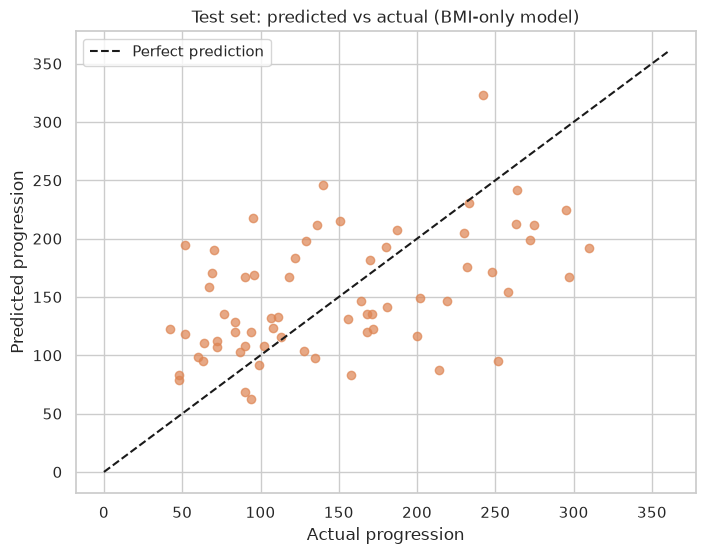

In [20]:
test_results = pd.DataFrame({"bmi": X_test_bmi["bmi"], "actual": y_test,
                             "predicted": best_bmi_model.predict(X_test_bmi)})
test_results["abs_error"] = (test_results["actual"] - test_results["predicted"]).abs()
test_results["progression_level"] = pd.cut(test_results["actual"], bins=[0, 100, 200, 400],
                                           labels=["Low (<100)", "Medium (100–200)", "High (>200)"])
display(test_results.groupby("progression_level", observed=True).agg(
    patients=("actual", "size"), mean_actual=("actual", "mean"),
    mean_predicted=("predicted", "mean"), MAE=("abs_error", "mean")))

plt.figure(figsize=(8, 6))
plt.scatter(test_results["actual"], test_results["predicted"], alpha=0.7, color="#DD8452")
lims = [0, 360]
plt.plot(lims, lims, "k--", label="Perfect prediction")
plt.xlabel("Actual progression"); plt.ylabel("Predicted progression")
plt.title("Test set: predicted vs actual (BMI-only model)")
plt.legend(); plt.show()

- **Regression to the mean:** the model's predictions only span about 65–325 and cluster around 150. It **overestimates low-progression patients** and, more importantly for screening, **underestimates high-progression patients**: the group with actual progression above 200 has the largest error, and their predictions are well below their true values. In the language of the *Performance Metrics* workshop, these are the costly **false negatives** of a screening tool.
- **High MAPE for low values:** patients with small progression (25–60) produce very large percentage errors, which explains why MAPE (≈49%) looks much worse than MAE suggests.
- **Same BMI, different outcomes:** the wide vertical spread in the plots shows that most of the variability depends on other factors (triglycerides, blood pressure, HDL…), which motivates Part 3.

**Limitations**
- Only one feature is used; important risk factors are ignored.
- Small sample (442 patients) and small validation/test sets → metrics vary considerably between splits (R² 0.20 to 0.45).
- Correlation is not causation: the slope describes an association in this cohort, not the effect of lowering a patient's BMI.
- The model produces a number, not a risk class. Turning it into a screening decision requires choosing a threshold (as in the *Logistic Regression* workshop) and checking recall on the high-risk group.
- Like any linear model it extrapolates without limit: for BMI values outside 18–42 the predictions are not supported by data.

# Part 3 – Multivariate Models

## Feature choice

**All ten features are used.** The EDA showed that several features carry useful information (`bmi`, `s5`, `bp`, `s4`, `s3`). `sex` and the correlated pair `s1`/`s2` are weak or redundant on their own, but they can still contribute in interactions and in tree splits, and with only ten features there is no strong reason to discard information. The effect of redundancy is discussed where it matters (the polynomial models).

**Scaling.** Multivariate polynomial terms, kNN distances and regularised logistic regression all depend on the scale of the inputs, so those pipelines start with a `StandardScaler` fitted on the training data. Decision trees split one feature at a time and are scale-invariant, so they use the raw values.

## 6. Models

| Family | Model A | Model B | What changes |
|---|---|---|---|
| Polynomial regression | degree 2 | degree 3 | flexibility (number of interaction terms) |
| Decision tree | `max_depth=3` | `max_depth=6` | depth of the tree |
| kNN regressor | `k=5` | `k=15` | number of neighbours averaged |
| Logistic regression | `C=1.0` | `C=0.01` | strength of L2 regularisation (smaller C = stronger) |

In [21]:
multi_models = {
    "Polynomial degree 2": Pipeline([("scaler", StandardScaler()),
                                     ("poly", PolynomialFeatures(degree=2, include_bias=True)),
                                     ("linreg", LinearRegression(fit_intercept=False))]),
    "Polynomial degree 3": Pipeline([("scaler", StandardScaler()),
                                     ("poly", PolynomialFeatures(degree=3, include_bias=True)),
                                     ("linreg", LinearRegression(fit_intercept=False))]),
    "Decision tree depth 3": DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE),
    "Decision tree depth 6": DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE),
    "kNN k=5": Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=5))]),
    "kNN k=15": Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=15))]),
}
for model in multi_models.values():
    model.fit(X_train, y_train)
print("Fitted:", list(multi_models))

Fitted: ['Polynomial degree 2', 'Polynomial degree 3', 'Decision tree depth 3', 'Decision tree depth 6', 'kNN k=5', 'kNN k=15']


## 7. Training vs validation comparison (regression models)

In [22]:
multi_table = train_val_table(multi_models, X_train, y_train, X_val, y_val)
display(multi_table)

,Train R²,Val R²,Train MAE,Val MAE,Train MAPE (%),Val MAPE (%)
Model,,,,,,
Polynomial degree 2,0.598,0.603,39.697,37.745,34.939,41.098
Polynomial degree 3,0.905,-82.520,16.541,273.023,15.234,165.083
Decision tree depth 3,0.533,0.413,43.588,42.078,37.748,43.651
Decision tree depth 6,0.787,0.163,25.998,51.210,22.941,49.784
kNN k=5,0.578,0.426,39.886,45.529,34.457,45.999
kNN k=15,0.489,0.553,44.509,40.188,39.289,41.171


**Reading the table**
- **Polynomial degree 2** gives the best validation scores of all regression models (R² ≈ 0.60, MAE ≈ 37.8), with training and validation R² almost equal – a sign of a good balance.
- **Polynomial degree 3 fails catastrophically**: training R² ≈ 0.91 but validation R² ≈ −83 (MAE ≈ 273). With 10 features it creates 286 terms for only 330 training patients, so it practically memorises the training set and produces absurd predictions on new patients. This is textbook **overfitting**.
- **Decision trees:** depth 3 generalises reasonably (validation R² ≈ 0.41); depth 6 also overfits (training 0.79 vs validation 0.16).
- **kNN:** `k=5` overfits more (training 0.58 vs validation 0.43) while `k=15` smooths the noise and reaches validation R² ≈ 0.55, illustrating the bias–variance role of *k* discussed in the kNN workshop.
- Most multivariate models beat the BMI-only model (validation R² 0.45), confirming that the other features add information.

In [23]:
multi_cv = cv_table(multi_models, X_trainval, y_trainval)
display(multi_cv)

,CV R² (mean),CV R² (std),CV MAE (mean),CV MAPE % (mean)
Model,,,,
Polynomial degree 2,0.277,0.112,51.152,43.341
Polynomial degree 3,-67.186,43.061,299.514,231.063
Decision tree depth 3,0.314,0.060,51.048,43.464
Decision tree depth 6,0.184,0.057,54.520,44.687
kNN k=5,0.343,0.035,48.799,42.481
kNN k=15,0.421,0.034,47.367,41.466


Cross-validation tells a different story for the top models:
- **kNN k=15 is the best model in cross-validation** (CV R² ≈ 0.42, CV MAE ≈ 47.4) and also the most stable (standard deviation ≈ 0.03 across folds).
- **Polynomial degree 2 drops to CV R² ≈ 0.28** with the largest variability among the reasonable models (std ≈ 0.11): its strong validation score depends on which 45 patients ended up in the validation set.
- Polynomial degree 3 and the depth-6 tree remain the worst models, confirming their overfitting.

## 8. Best regression model

In [24]:
ranking = pd.DataFrame({"Val R² rank": multi_table["Val R²"].rank(ascending=False).astype(int),
                        "CV R² rank": multi_cv["CV R² (mean)"].rank(ascending=False).astype(int)})
display(ranking.sort_values("CV R² rank"))

# Validation and cross-validation disagree on the winner, so cross-validation decides (rule in step 8 of Part 2).
best_multi_name = multi_cv["CV R² (mean)"].idxmax()
best_multi_model = multi_models[best_multi_name]
print("Highest validation R²:", multi_table["Val R²"].idxmax())
print("Highest cross-validated R²:", best_multi_name)
print("Selected model:", best_multi_name)
display(multi_table.loc[[best_multi_name]])

,Val R² rank,CV R² rank
Model,,
kNN k=15,2,1
kNN k=5,3,2
Decision tree depth 3,4,3
Polynomial degree 2,1,4
Decision tree depth 6,5,5
Polynomial degree 3,6,6


Highest validation R²: Polynomial degree 2
Highest cross-validated R²: kNN k=15
Selected model: kNN k=15


,Train R²,Val R²,Train MAE,Val MAE,Train MAPE (%),Val MAPE (%)
Model,,,,,,
kNN k=15,0.489,0.553,44.509,40.188,39.289,41.171


**Selected model: kNN with k = 15.** Polynomial degree 2 wins on the single validation set (R² 0.60 vs 0.55), but kNN k=15 is second there, first in cross-validation (0.42 vs 0.28) and much more stable across folds. Following the selection rule, the 5-fold evidence on 375 patients outweighs one 45-patient validation set. The decision is made **before** looking at the test set.

## 9. Test-set evaluation of the chosen regression model

In [25]:
multi_comparison = pd.DataFrame([regression_metrics(best_multi_model, X_train, y_train),
                                 regression_metrics(best_multi_model, X_val, y_val),
                                 regression_metrics(best_multi_model, X_test, y_test)],
                                index=["Train", "Validation", "Test"])
display(multi_comparison)

# For reference only: every regression model on the test set (not used for selection)
display(pd.DataFrame({name: regression_metrics(m, X_test, y_test) for name, m in multi_models.items()}).T)

,R²,MAE,MAPE (%)
Train,0.489,44.509,39.289
Validation,0.553,40.188,41.171
Test,0.411,46.278,42.294


,R²,MAE,MAPE (%)
Polynomial degree 2,0.337,45.867,39.474
Polynomial degree 3,-35.669,234.105,202.068
Decision tree depth 3,0.308,50.371,44.903
Decision tree depth 6,0.088,54.092,42.944
kNN k=5,0.391,45.379,38.361
kNN k=15,0.411,46.278,42.294


**Test results (kNN k=15):** R² ≈ 0.41, MAE ≈ 46.3 points, MAPE ≈ 42.3%. Compared with the BMI-only model on the same test set (R² 0.20, MAE 54.9, MAPE 48.8%) this is a clear improvement: about **9 points less average error** and twice the explained variance. The test R² (0.41) is very close to the cross-validated estimate (0.42), which supports the decision to trust cross-validation.

The second table is shown only for transparency, after the selection was made; it is not used to choose. It confirms that the high-capacity models (polynomial degree 3, tree depth 6) fail on unseen patients, and that polynomial degree 2 falls from validation R² 0.60 to test R² 0.34.

## 10. Plots

As stated in the assignment, plots of the multivariate models are not required. A predicted-vs-actual chart is included in the conclusions to support the failure analysis.

## 11. Equations / model descriptions

In [26]:
# Polynomial degree 2: 66 terms on standardised features (z_x = (x - mean_train) / std_train)
poly2 = multi_models["Polynomial degree 2"]
terms = poly2.named_steps["poly"].get_feature_names_out(X.columns)
coef = pd.Series(poly2.named_steps["linreg"].coef_, index=terms)
print(f"Polynomial degree 2 has {len(coef)} terms. Intercept (term '1'): {coef['1']:.2f}")
print("Ten largest terms by absolute value (standardised units):")
display(coef.drop("1").reindex(coef.drop("1").abs().sort_values(ascending=False).index).head(10).round(2).to_frame("Coefficient"))

Polynomial degree 2 has 66 terms. Intercept (term '1'): -23.00
Ten largest terms by absolute value (standardised units):


,Coefficient
s1,"-2,112.840"
s2,"1,850.950"
s3,795.470
s5,721.320
s1 s5,197.860
s2 s5,-193.340
s1 s2,-120.220
s1^2,105.410
s5^2,97.050
s3 s5,-83.240


**Polynomial degree 2.** The equation has the form

**predicted progression = β₀ + Σᵢ βᵢ·zᵢ + Σᵢ≤ⱼ βᵢⱼ·zᵢ·zⱼ**

where each zᵢ is a standardised feature (the sums run over all features and all pairs of features, including squares). It contains 66 coefficients, so writing every term is not useful for a reader; the table above lists the intercept and the ten largest coefficients with two decimals. The linear terms of `s1`, `s2`, `s3` and `s4` are very large and of opposite signs – a direct consequence of the multicollinearity found in the EDA (they partly cancel each other) – so individual coefficients should not be interpreted clinically.

In [27]:
print("Decision tree depth 3 – learned rules (each leaf value is the predicted progression):\n")
print(export_text(multi_models["Decision tree depth 3"], feature_names=list(X.columns), decimals=2))

Decision tree depth 3 – learned rules (each leaf value is the predicted progression):

|--- bmi <= 27.25
|   |--- s5 <= 4.79
|   |   |--- s5 <= 4.17
|   |   |   |--- value: [77.92]
|   |   |--- s5 >  4.17
|   |   |   |--- value: [115.72]
|   |--- s5 >  4.79
|   |   |--- s6 <= 98.50
|   |   |   |--- value: [155.13]
|   |   |--- s6 >  98.50
|   |   |   |--- value: [215.93]
|--- bmi >  27.25
|   |--- bmi <= 33.15
|   |   |--- bp <= 99.50
|   |   |   |--- value: [171.75]
|   |   |--- bp >  99.50
|   |   |   |--- value: [224.79]
|   |--- bmi >  33.15
|   |   |--- s2 <= 129.80
|   |   |   |--- value: [294.79]
|   |   |--- s2 >  129.80
|   |   |   |--- value: [224.14]



**Decision tree.** A tree has no single equation; it is a set of if–then rules. The shallow tree first splits on **`bmi`** (at 27.25) and then on **`s5`** (triglycerides), `bp`, `s6` and `s2` – the same features the EDA identified as most important. Its leaves go from about 78 (low BMI and low triglycerides) to about 295 (BMI above 33).

**kNN k=15 (the selected model)** has no equation. Its prediction rule is:

**predicted progression(x) = (1/15) × sum of the progression of the 15 nearest training patients**

where the nearest patients are the 15 training patients closest to the new patient x in Euclidean distance, measured on the standardised features.

## 12. Prediction for a chosen patient

For the multivariate models, a "typical" patient is used: every feature at its training-set **median**, except BMI, which is set to 30 kg/m² to match the example in Part 2.

In [28]:
patient = X_train.median().to_frame().T
patient["bmi"] = 30.0
display(patient)
preds = {name: model.predict(patient)[0] for name, model in multi_models.items()}
preds["BMI-only linear model (Part 2)"] = best_bmi_model.predict(patient[["bmi"]])[0]
display(pd.Series(preds, name="Predicted progression").round(2).to_frame())

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,50.000,1.000,30.000,93.000,186.000,112.300,48.000,4.000,4.630,91.000


,Predicted progression
Polynomial degree 2,-146.760
Polynomial degree 3,"15,890.790"
Decision tree depth 3,171.750
Decision tree depth 6,140.660
kNN k=5,218.000
kNN k=15,185.600
BMI-only linear model (Part 2),192.170


The selected **kNN k=15** model predicts a progression of about **186** for this patient, consistent with the BMI-only model (192), the shallow tree (172) and kNN k=5 (218).

The polynomial models show why they were not selected: polynomial degree 2 predicts about **−147**, which is impossible (progression is always positive), and degree 3 predicts about 15,891. This patient is ordinary – every feature is at its median except BMI – but the combination does not exist exactly in the training data, and the many interaction terms with large, opposite-signed coefficients extrapolate wildly. kNN, by construction, can only predict values inside the range of real patients.

## 13. Trainable parameters

In [29]:
rows = []
for name, model in multi_models.items():
    if "Polynomial" in name:
        n_params = len(model.named_steps["poly"].get_feature_names_out())
        note = "one coefficient per polynomial term (incl. intercept)"
    elif "tree" in name:
        tree = model.tree_
        n_internal = int((tree.children_left != -1).sum())
        n_leaves = int(model.get_n_leaves())
        n_params = 2 * n_internal + n_leaves
        note = f"{n_internal} splits × (feature + threshold) + {n_leaves} leaf values"
    else:
        n_params = 0
        note = "no fitted weights; stores all 330 training patients (and the scaler's means/stds)"
    rows.append({"Model": name, "Learned parameters": n_params, "Explanation": note})
display(pd.DataFrame(rows).set_index("Model"))

,Learned parameters,Explanation
Model,,
Polynomial degree 2,66,one coefficient per polynomial term (incl. int...
Polynomial degree 3,286,one coefficient per polynomial term (incl. int...
Decision tree depth 3,22,7 splits × (feature + threshold) + 8 leaf values
Decision tree depth 6,172,57 splits × (feature + threshold) + 58 leaf va...
kNN k=5,0,no fitted weights; stores all 330 training pat...
kNN k=15,0,no fitted weights; stores all 330 training pat...


- **Polynomial models:** with 10 features, degree 2 creates 1 constant + 10 linear + 10 squared + 45 pairwise interactions = **66** coefficients; degree 3 adds all cubic combinations, reaching **286** coefficients – close to the 330 training patients, which explains its overfitting.
- **Decision trees** are non-parametric: the number of learned values grows with depth. Each split learns which feature to use and a threshold, and each leaf stores a predicted value. The depth-6 tree learns several times more values than the depth-3 tree.
- **kNN** learns no weights at all: "training" means storing the data (plus 20 scaling statistics). The only choice is the hyperparameter *k*.

## 14. Conclusions for the regression models of Part 3

- Using all features raises performance compared with BMI alone (test MAE ≈ 46 vs ≈ 55; cross-validated R² ≈ 0.42 vs ≈ 0.34).
- **Model complexity must match the amount of data**: the degree-3 polynomial and the depth-6 tree memorise the 330 training patients and fail on new ones; simpler models generalise better.
- A model can look best on one small validation set and still be unstable: polynomial degree 2 was first on validation, but cross-validation, the test set and the impossible negative prediction all exposed it.
- kNN works well once the features are standardised and *k* is large enough; it is easy to explain ("patients like you progressed by X") but needs the whole training set at prediction time.

## Logistic Regression models (classification framing)

### 6. Framing and models

Logistic regression is a **classifier**, so the continuous target is converted into two classes:

- **High risk (1):** progression greater than the **training-set median** (142).
- **Low risk (0):** progression ≤ 142.

The median is computed on the training data only (no leakage) and gives two balanced classes, so accuracy is not distorted by class imbalance. In a real deployment the threshold should be agreed with physicians.

Because the output is a class, **R², MAE and MAPE do not apply**. Following the *Performance Metrics Classification* workshop, the models are compared with **accuracy, precision, recall, F1-score and ROC-AUC**, and the chosen model is inspected with a **confusion matrix**. Recall on the high-risk class is the most important metric for screening.

Two models are compared: `C=1.0` (default, mild regularisation) and `C=0.01` (strong L2 regularisation, which shrinks coefficients – useful with correlated features such as `s1`/`s2`).

In [30]:
risk_threshold = y_train.median()
print(f"High-risk threshold (training median): {risk_threshold:.1f}")
yc_train, yc_val, yc_test = (y_train > risk_threshold).astype(int), (y_val > risk_threshold).astype(int), (y_test > risk_threshold).astype(int)
yc_trainval = (y_trainval > risk_threshold).astype(int)
print("Share of high-risk patients – train / val / test:",
      f"{yc_train.mean():.2f} / {yc_val.mean():.2f} / {yc_test.mean():.2f}")

logit_models = {
    "Logistic C=1.0": Pipeline([("scaler", StandardScaler()),
                                ("logreg", LogisticRegression(C=1.0, max_iter=1000))]),
    "Logistic C=0.01": Pipeline([("scaler", StandardScaler()),
                                 ("logreg", LogisticRegression(C=0.01, max_iter=1000))]),
}
for model in logit_models.values():
    model.fit(X_train, yc_train)

High-risk threshold (training median): 142.0
Share of high-risk patients – train / val / test: 0.49 / 0.49 / 0.45


### 7. Training vs validation comparison (classification metrics)

In [31]:
def classification_metrics(model, X_, y_):
    pred = model.predict(X_)
    proba = model.predict_proba(X_)[:, 1]
    return {"Accuracy": accuracy_score(y_, pred), "Precision": precision_score(y_, pred),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred), "ROC-AUC": roc_auc_score(y_, proba)}

rows = []
for name, model in logit_models.items():
    for set_name, Xs, ys in [("Train", X_train, yc_train), ("Validation", X_val, yc_val)]:
        rows.append({"Model": name, "Set": set_name, **classification_metrics(model, Xs, ys)})
logit_table = pd.DataFrame(rows).set_index(["Model", "Set"])
display(logit_table)

cv_rows = []
for name, model in logit_models.items():
    s = cross_validate(model, X_trainval, yc_trainval, cv=CV, scoring=["accuracy", "recall", "f1", "roc_auc"])
    cv_rows.append({"Model": name, "CV Accuracy": s["test_accuracy"].mean(), "CV Recall": s["test_recall"].mean(),
                    "CV F1": s["test_f1"].mean(), "CV ROC-AUC": s["test_roc_auc"].mean()})
display(pd.DataFrame(cv_rows).set_index("Model"))

Accuracy  Precision  Recall    F1  ROC-AUC
Model           Set                                                   
Logistic C=1.0  Train          0.730      0.724   0.728 0.726    0.841
                Validation     0.822      0.792   0.864 0.826    0.919
Logistic C=0.01 Train          0.727      0.720   0.728 0.724    0.824
                Validation     0.844      0.826   0.864 0.844    0.925

,CV Accuracy,CV Recall,CV F1,CV ROC-AUC
Model,,,,
Logistic C=1.0,0.728,0.736,0.723,0.842
Logistic C=0.01,0.715,0.718,0.706,0.830


Both models perform similarly: training accuracy ≈ 0.73, validation accuracy 0.82–0.84, the same validation recall (0.86) and validation ROC-AUC above 0.9. `C=0.01` is slightly better on the 45-patient validation set (F1 0.844 vs 0.826), while `C=1.0` is better in 5-fold cross-validation on every metric (F1 0.723 vs 0.706, recall 0.736 vs 0.718). Strong regularisation shrinks the coefficients so much that the model loses some signal.

### 8–9. Best logistic model and test results

Highest validation F1: Logistic C=0.01
Highest cross-validated F1: Logistic C=1.0
Selected logistic model: Logistic C=1.0


,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic C=1.0 – Test,0.746,0.710,0.733,0.721,0.824


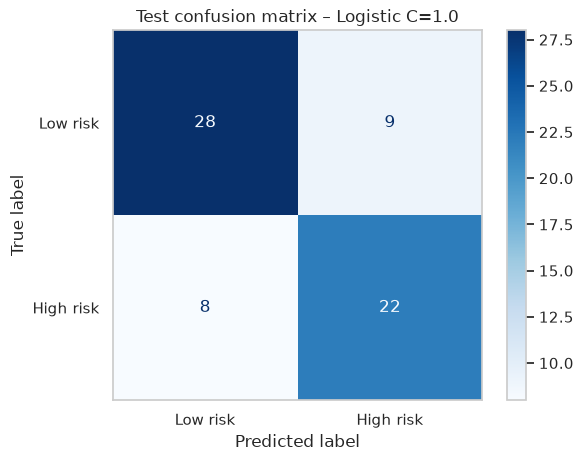

In [32]:
val_f1 = logit_table.xs("Validation", level="Set")["F1"]
cv_f1 = pd.DataFrame(cv_rows).set_index("Model")["CV F1"]
print("Highest validation F1:", val_f1.idxmax())
print("Highest cross-validated F1:", cv_f1.idxmax())
best_logit_name = cv_f1.idxmax()   # same selection rule: cross-validation decides on disagreement
best_logit = logit_models[best_logit_name]
print("Selected logistic model:", best_logit_name)

display(pd.DataFrame([classification_metrics(best_logit, X_test, yc_test)], index=[f"{best_logit_name} – Test"]))

ConfusionMatrixDisplay.from_estimator(best_logit, X_test, yc_test,
                                      display_labels=["Low risk", "High risk"], cmap="Blues")
plt.title(f"Test confusion matrix – {best_logit_name}")
plt.grid(False)
plt.show()

Following the same selection rule as the regression models, cross-validation decides: **`C=1.0` is selected**.

**Test results (`C=1.0`):** accuracy ≈ 0.75, precision ≈ 0.71, recall ≈ 0.73, F1 ≈ 0.72, ROC-AUC ≈ 0.82. The confusion matrix shows that **8 of the 30 high-risk test patients are classified as low risk** (false negatives) and 9 low-risk patients are flagged unnecessarily (false positives). For a screening tool the false negatives are the error to reduce: as discussed in the *Logistic Regression* workshop, lowering the decision threshold below 0.5 would flag more patients, increasing recall at the cost of more false positives.

### 11. Equation of the logistic model

In [33]:
lr = best_logit.named_steps["logreg"]
logit_coef = pd.Series(lr.coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
print(f"Intercept: {lr.intercept_[0]:.2f}")
display(logit_coef.round(2).to_frame("Coefficient (standardised feature)"))
terms = " ".join(f"{'+' if c >= 0 else '-'} {abs(c):.2f}·z_{n}" for n, c in logit_coef.items())
print(f"log-odds(high risk) = {lr.intercept_[0]:.2f} {terms}")
print("P(high risk) = 1 / (1 + exp(-log-odds))")

Intercept: -0.01


,Coefficient (standardised feature)
s5,0.750
bmi,0.650
sex,-0.590
bp,0.560
s1,-0.470
s3,-0.320
age,0.240
s4,0.160
s6,0.060
s2,0.030


log-odds(high risk) = -0.01 + 0.75·z_s5 + 0.65·z_bmi - 0.59·z_sex + 0.56·z_bp - 0.47·z_s1 - 0.32·z_s3 + 0.24·z_age + 0.16·z_s4 + 0.06·z_s6 + 0.03·z_s2
P(high risk) = 1 / (1 + exp(-log-odds))


The largest positive coefficients belong to **`s5`** (triglycerides) and **`bmi`**, followed by `bp`; `s3` (HDL, "good" cholesterol) has a negative coefficient. This matches the EDA: higher triglycerides, BMI and blood pressure raise the odds of being high-risk, and higher HDL lowers them. Because the features are standardised, each coefficient is the change in log-odds for a one-standard-deviation increase. The negative `sex` and `s1` coefficients should be read with caution: `sex` is a 1/2 code with almost no correlation with the target, and `s1` is strongly correlated with `s2`, so their individual values partly reflect adjustments between correlated features.

### 12. Prediction for the chosen patient

In [34]:
p_high = best_logit.predict_proba(patient)[0, 1]
print(f"Patient with median features and BMI = 30: P(high risk) = {p_high:.2f} → "
      f"class: {'High risk' if p_high >= 0.5 else 'Low risk'}")

Patient with median features and BMI = 30: P(high risk) = 0.75 → class: High risk


### 13. Trainable parameters

Each logistic model learns **11 parameters**: one coefficient per feature (10) plus the intercept. Both models have the same number of parameters; regularisation does not remove parameters, it limits how large they can become.

In [35]:
for name, model in logit_models.items():
    lr_ = model.named_steps["logreg"]
    print(f"{name}: {lr_.coef_.size} coefficients + {lr_.intercept_.size} intercept = {lr_.coef_.size + lr_.intercept_.size} parameters")

Logistic C=1.0: 10 coefficients + 1 intercept = 11 parameters
Logistic C=0.01: 10 coefficients + 1 intercept = 11 parameters


# Final Conclusions

## Summary of the selected models

In [36]:
summary = pd.DataFrame({
    "Part 2 – BMI-only linear (Degree 1)": regression_metrics(best_bmi_model, X_test_bmi, y_test),
    f"Part 3 – {best_multi_name}": regression_metrics(best_multi_model, X_test, y_test),
}).T
display(summary)

,R²,MAE,MAPE (%)
Part 2 – BMI-only linear (Degree 1),0.204,54.934,48.750
Part 3 – kNN k=15,0.411,46.278,42.294


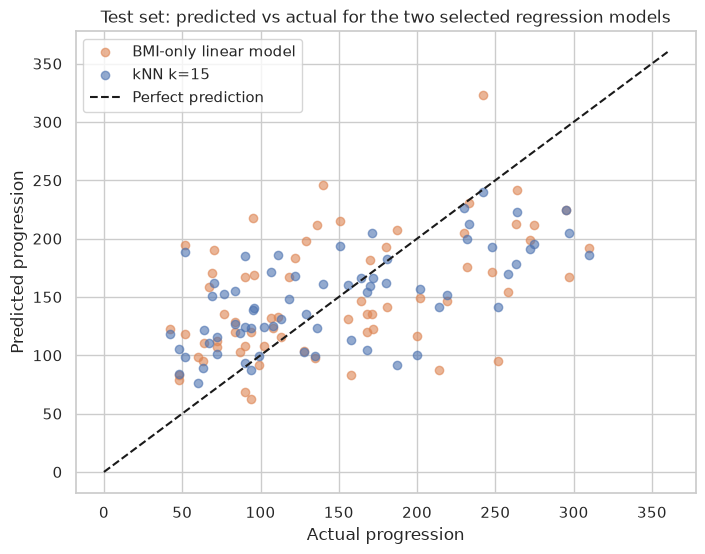

In [37]:
pred_multi = best_multi_model.predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_bmi_model.predict(X_test_bmi), alpha=0.6, label="BMI-only linear model", color="#DD8452")
plt.scatter(y_test, pred_multi, alpha=0.6, label=best_multi_name, color="#4C72B0")
plt.plot([0, 360], [0, 360], "k--", label="Perfect prediction")
plt.xlabel("Actual progression"); plt.ylabel("Predicted progression")
plt.title("Test set: predicted vs actual for the two selected regression models")
plt.legend(); plt.show()

**Performance**
- BMI alone explains a limited part of disease progression (test R² 0.20, MAE ≈ 55). Its relation with progression is linear; higher polynomial degrees do not help.
- Using all ten features improves every metric: the selected **kNN with k = 15** reaches test R² 0.41, MAE ≈ 46 and MAPE ≈ 42%, and its test R² matches its cross-validated estimate (0.42).
- As a classifier, logistic regression (`C=1.0`) separates high- and low-risk patients with ≈ 75% accuracy, 73% recall and ROC-AUC ≈ 0.82 on the test set.

**Where the models fail**
- All regression models **compress predictions toward the mean**: they underestimate the patients with the highest progression (above ~250) and overestimate those with the lowest. For a screening tool, the underestimation of high-risk patients is the most serious failure, because it is equivalent to a false negative.
- Percentage errors are very large for patients with low progression, so MAPE alone gives a pessimistic picture; MAE and a breakdown by risk level are more informative.
- High-capacity models (polynomial degree 3, tree depth 6) overfit dramatically given only 330 training patients, and the multivariate polynomials can even produce impossible negative predictions for ordinary patients.

**Limitations**
- **Small dataset:** 442 patients, with validation and test sets of 45 and 67. Metrics change noticeably between splits (the BMI model scored R² 0.45 on validation but 0.20 on test). Cross-validation reduces, but does not remove, this uncertainty, and a larger external dataset would be needed before clinical use.
- **Limited and anonymised features:** only ten baseline measurements; no information on medication, diet, physical activity or genetics.
- **Association, not causation:** the models describe patterns in this cohort; they do not show that changing a feature would change a patient's progression.
- **Threshold choice:** the high-risk cut-off (training median = 142) is a statistical choice, not a clinical one.

**Talking points from the workshops**
- *Performance Metrics:* for screening, the confusion matrix and recall matter more than overall accuracy; reducing false negatives should guide the final decision threshold.
- *K-Nearest Neighbors:* scaling the features was essential, and *k* acted as the bias–variance knob (k=5 overfitted, k=15 generalised better).
- *Logistic Regression:* it provides interpretable risk factors (`s5`, `bmi`, `bp` up; `s3` down) and a probability for each patient, and its threshold can be tuned to the clinical cost of missing a patient.

**Recommendation.** Use kNN (k = 15) for a numeric estimate of progression and logistic regression for a high-risk flag, as a **support** to the physician's judgement and never as the only decision criterion. If the priority is to miss as few at-risk patients as possible, lower the classification threshold.